In [ ]:
# Implement an RNN for Text Classification CO3
# o Use IMDB sentiment classification dataset.
# o Implement an LSTM for binary classification.
# o Plot accuracy and visualize example predictions.

In [ ]:
# Import libraries
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

I0000 00:00:1794548353.052023    4337 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794548358.149434    4337 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794548371.850743    4337 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:

# Load and preprocess IMDB Dataset
df = pd.read_csv("dataset/IMDB/IMDB Dataset.csv")

df = df.dropna(subset=['review', 'sentiment'])
df = df.drop_duplicates()

df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})

tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=10000)
tokenizer.fit_on_texts(df['review'])

x = tf.keras.preprocessing.sequence.pad_sequences(
    tokenizer.texts_to_sequences(df['review']), maxlen=200)

y = df['sentiment'].values

x_train, x_test = x[:40000], x[40000:]
y_train, y_test = y[:40000], y[40000:]

print("Training:", x_train.shape)
print("Testing:", x_test.shape)
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Training: (40000, 200)
Testing: (9582, 200)
Dataset shape: (49582, 2)
Duplicate rows: 0


In [ ]:
# Build and train SimpleRNN
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(10000, 32),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

E0000 00:00:1794474355.073639    7329 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
W0000 00:00:1794474355.230576    7329 cpu_allocator_impl.cc:82] Allocation of 28800000 exceeds 10% of free system memory.


Epoch 1/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 49s 83ms/step - accuracy: 0.7012 - loss: 0.5494 - val_accuracy: 0.8190 - val_loss: 0.4087
Epoch 2/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 46s 83ms/step - accuracy: 0.8652 - loss: 0.3291 - val_accuracy: 0.8535 - val_loss: 0.3687
Epoch 3/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 45s 80ms/step - accuracy: 0.9132 - loss: 0.2288 - val_accuracy: 0.8510 - val_loss: 0.3797
Epoch 4/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.9392 - loss: 0.1641 - val_accuracy: 0.8395 - val_loss: 0.4540
Epoch 5/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 47s 84ms/step - accuracy: 0.9713 - loss: 0.0900 - val_accuracy: 0.8382 - val_loss: 0.4863


In [ ]:
# Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")
print("Test Loss:", loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8384 - loss: 0.4929
Test Accuracy: 83.84000062942505 %
Test Loss: 0.49290621280670166


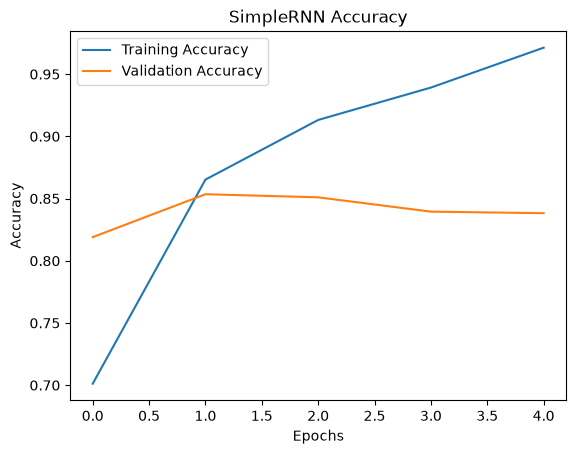

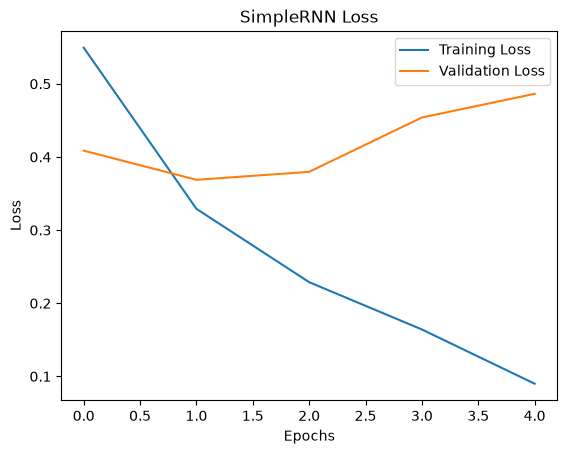

In [ ]:
# Plot accuracy and loss
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("SimpleRNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("SimpleRNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
# Predict example reviews
reviews = [
    "This movie was amazing and I really enjoyed it",
    "This movie was terrible and very boring",
    "The acting was excellent and the story was wonderful"
]

seq = tf.keras.preprocessing.sequence.pad_sequences(
    tokenizer.texts_to_sequences(reviews), maxlen=200)

predictions = model.predict(seq)

for review, pred in zip(reviews, predictions):
    print(review, ":", "Positive" if pred[0] >= 0.5 else "Negative")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step
This movie was amazing and I really enjoyed it : Positive
This movie was terrible and very boring : Negative
The acting was excellent and the story was wonderful : Positive
